# Student Placement Outcomes — A Reporting Notebook

## Project snapshot

| | |
|---|---|
| **Question** | What share of students are placed, what package do placed students receive, and which cuts actually change those two numbers? |
| **Data** | Kaggle's [Student Placement Prediction Dataset 2026](https://www.kaggle.com/datasets/sehaj1104/student-placement-prediction-dataset-2026). The publisher describes the file as synthetic. |
| **Method** | Check the file, apply one cleaning rule, run the group totals in SQL, then show the KPIs, a pivot, three charts, and a short correlation check. |
| **Result** | 54.5% are placed. Among placed students the mean package is 13.32 LPA and the median is 13.30 LPA. Branch rates sit between 54.1% and 55.2%. |

This is a reporting exercise. It is not a hiring study and it is not a pay formula.

## Skills this notebook shows

| Skill | Where |
|---|---|
| Checking data quality | Section 1 |
| Cleaning with a written rule, and naming the fields | Section 2 |
| SQL `GROUP BY`, `CASE`, and a window function | Section 3 |
| KPI tables and an Excel-style pivot | Section 4 |
| Charts | Section 5 |
| A short correlation check | Section 6 |

The code is ordinary pandas, matplotlib, seaborn, and `sqlite3`. The queries run in memory. Nothing is exported.


In [1]:
from IPython import get_ipython

ipython = get_ipython()
if ipython is not None:
    ipython.run_line_magic("matplotlib", "inline")

import random
import sqlite3

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import kagglehub

random.seed(42)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)


## 1. Load the file and check it

A rate is one count divided by another. A package only makes sense if it belongs to the right status. Duplicate rows, missing values, impossible numbers, or a placed student with no salary would flow into every table below. Those checks come first, before any percentage is quoted.

The bounds used here are set in advance: CGPA on the documented 4.5 to 10 scale, scores and attendance from 0 to 100, sleep and study hours from 0 to 24, age from 15 to 30, and counts and salary at zero or above. A salary of zero is allowed by that last rule. It is checked again against placement status.


In [2]:
folder = kagglehub.dataset_download("sehaj1104/student-placement-prediction-dataset-2026")
df = pd.read_csv(folder + "/student_placement_prediction_dataset_2026.csv")

print("Rows:", len(df))
print("Columns:", df.shape[1])
df.head()


Rows: 100000
Columns: 26


,student_id,age,gender,cgpa,branch,college_tier,internships_count,projects_count,certifications_count,coding_skill_score,aptitude_score,communication_skill_score,logical_reasoning_score,hackathons_participated,github_repos,linkedin_connections,mock_interview_score,attendance_percentage,backlogs,extracurricular_score,leadership_score,volunteer_experience,sleep_hours,study_hours_per_day,placement_status,salary_package_lpa
0,1,24,Male,7.53,IT,Tier 2,4,6,1,99.238568,81.707722,57.707166,59.070073,4,1,184,72.647009,77.463863,2,63.382726,52.938240,Yes,6.7,3.6,Not Placed,0.00
1,2,21,Male,7.92,CSE,Tier 2,1,3,6,80.966123,63.116715,59.197085,78.976419,0,2,539,61.699110,88.887600,1,73.694605,60.198856,No,4.4,2.3,Not Placed,0.00
2,3,22,Female,8.60,EEE,Tier 1,0,1,1,49.177184,48.658753,92.104885,80.603331,0,2,568,87.396911,74.153265,0,63.329294,43.708803,No,8.8,5.9,Placed,11.99
3,4,24,Male,6.68,CSE,Tier 1,0,2,2,79.359084,66.376653,83.411798,64.187246,1,1,550,58.401069,87.635955,1,47.636099,56.549154,Yes,8.1,4.4,Not Placed,0.00
4,5,20,Female,8.43,IT,Tier 3,1,4,3,65.018573,61.274985,88.956331,56.163678,1,4,833,74.489201,79.120749,1,0.000000,67.268893,No,8.7,3.4,Placed,12.16


Each row is one student. The columns mix an identifier, academic and activity fields, `placement_status`, and `salary_package_lpa`. There are 100,000 rows and 26 columns, so the rates below are not coming from a small sample.


In [3]:
print("Duplicate rows:", int(df.duplicated().sum()))
print("Duplicate student_id:", int(df["student_id"].duplicated().sum()))
print("Missing values:", int(df.isnull().sum().sum()))
df.isnull().sum()


Duplicate rows: 0
Duplicate student_id: 0
Missing values: 0


student_id                   0
age                          0
gender                       0
cgpa                         0
branch                       0
college_tier                 0
internships_count            0
projects_count               0
certifications_count         0
coding_skill_score           0
aptitude_score               0
communication_skill_score    0
logical_reasoning_score      0
hackathons_participated      0
github_repos                 0
linkedin_connections         0
mock_interview_score         0
attendance_percentage        0
backlogs                     0
extracurricular_score        0
leadership_score             0
volunteer_experience         0
sleep_hours                  0
study_hours_per_day          0
placement_status             0
salary_package_lpa           0
dtype: int64

There are no duplicate rows and no duplicate student IDs, so each row can be treated as one student. There are no missing values, so nothing needs to be filled in. A later average will not be changed by a hidden blank.


In [4]:
# low, high. None means there is no upper limit.
rules = [
    ("age", 15, 30),
    ("cgpa", 4.5, 10),
    ("internships_count", 0, None),
    ("projects_count", 0, None),
    ("certifications_count", 0, None),
    ("coding_skill_score", 0, 100),
    ("aptitude_score", 0, 100),
    ("communication_skill_score", 0, 100),
    ("logical_reasoning_score", 0, 100),
    ("hackathons_participated", 0, None),
    ("github_repos", 0, None),
    ("linkedin_connections", 0, None),
    ("mock_interview_score", 0, 100),
    ("attendance_percentage", 0, 100),
    ("backlogs", 0, None),
    ("extracurricular_score", 0, 100),
    ("leadership_score", 0, 100),
    ("sleep_hours", 0, 24),
    ("study_hours_per_day", 0, 24),
    ("salary_package_lpa", 0, None),
]

range_rows = []
for col, low, high in rules:
    if high is None:
        n_bad = int((df[col] < low).sum())
        rule_text = str(low) + " or more"
    else:
        n_bad = int(((df[col] < low) | (df[col] > high)).sum())
        rule_text = str(low) + " to " + str(high)
    range_rows.append({
        "column": col,
        "rule": rule_text,
        "out_of_range": n_bad,
        "min": df[col].min(),
        "max": df[col].max(),
    })

range_check = pd.DataFrame(range_rows)
range_check


,column,rule,out_of_range,min,max
0,age,15 to 30,0,18.0,24.00
1,cgpa,4.5 to 10,0,4.5,10.00
2,internships_count,0 or more,0,0.0,8.00
3,projects_count,0 or more,0,0.0,13.00
4,certifications_count,0 or more,0,0.0,11.00
5,coding_skill_score,0 to 100,0,20.0,100.00
6,aptitude_score,0 to 100,0,20.0,100.00
7,communication_skill_score,0 to 100,0,20.0,100.00
8,logical_reasoning_score,0 to 100,0,20.0,100.00
9,hackathons_participated,0 or more,0,0.0,8.00


No numeric value falls outside those rules. Age runs from 18 to 24, inside the 15 to 30 screen. CGPA stays on 4.5 to 10. Scores stay inside 0 to 100. Counts are never negative. The bands later in the notebook are not being pulled around by an impossible row.

A salary of 0 still passes this table, because 0 is a real recorded value. The next check asks whether that 0 lines up with placement status.


In [5]:
text_cols = ["gender", "branch", "college_tier", "volunteer_experience", "placement_status"]
for col in text_cols:
    blanks = int(df[col].isna().sum())
    blanks = blanks + int((df[col].astype(str).str.strip() == "").sum())
    print(col, "blank labels:", blanks)

conn = sqlite3.connect(":memory:")
df.to_sql("students", conn, index=False)

status_sql = '''
SELECT
    SUM(CASE WHEN placement_status = 'Not Placed' THEN 1 ELSE 0 END) AS not_placed,
    SUM(CASE WHEN placement_status = 'Placed' THEN 1 ELSE 0 END) AS placed,
    SUM(CASE WHEN placement_status = 'Not Placed' AND salary_package_lpa <> 0 THEN 1 ELSE 0 END) AS not_placed_with_pay,
    SUM(CASE WHEN placement_status = 'Placed' AND salary_package_lpa <= 0 THEN 1 ELSE 0 END) AS placed_without_pay
FROM students
'''
pd.read_sql_query(status_sql, conn)


gender blank labels: 0
branch blank labels: 0
college_tier blank labels: 0
volunteer_experience blank labels: 0
placement_status blank labels: 0


,not_placed,placed,not_placed_with_pay,placed_without_pay
0,45541,54459,0,0


The text fields have no blank labels, and placement status has only the two expected values. The query counts 45,541 students who are not placed and 54,459 who are placed. None of the unplaced students has a salary other than 0, and none of the placed students has a salary of 0 or below.

That means the zero salaries are structural: the file uses 0 to mean "no package", not "missing". An average salary taken over all 100,000 rows would mix real packages with those 45,541 zeros. Pay figures below use placed students only.


## 2. Clean with one written rule

`student_id` is useful for the duplicate check and useless as a measurement. Once the IDs are confirmed unique, the column is dropped so it cannot be averaged by accident. No row is deleted. The zero salaries stay, because deleting them would remove the unplaced students and change the placement rate.


In [6]:
print("Rows before:", len(df))
print("Duplicate student_id before drop:", int(df["student_id"].duplicated().sum()))

df = df.drop(columns=["student_id"])

print("Rows after:", len(df))
print("Columns after:", df.shape[1])

unplaced = df[df["placement_status"] == "Not Placed"]
print("Unplaced rows still in the table:", len(unplaced))
print("Their salary is still all zero:", bool((unplaced["salary_package_lpa"] == 0).all()))

df.to_sql("students", conn, index=False, if_exists="replace")


Rows before: 100000
Duplicate student_id before drop: 0
Rows after: 100000
Columns after: 25
Unplaced rows still in the table: 45541
Their salary is still all zero: True


100000

Cleaning removed one column and no rows. The table still has 100,000 students, including all 45,541 unplaced students at 0 LPA. Nothing was imputed, because nothing was missing.


In [7]:
field_notes = pd.DataFrame([
    ["placement_status", "Placed or Not Placed", "Used for the placement rate"],
    ["salary_package_lpa", "Package in LPA. It is 0 when the student is not placed", "Used for pay, on placed rows only"],
    ["branch", "Field of study", "Slice and pivot row"],
    ["college_tier", "Tier 1, Tier 2, or Tier 3", "Slice and pivot column"],
    ["gender", "Female or Male", "Slice"],
    ["volunteer_experience", "Yes or No", "Slice"],
    ["cgpa", "Grade point average, 4.5 to 10", "Band and correlation"],
    ["backlogs", "Count of failed subjects", "Band"],
    ["internships_count", "Count of internships", "Band and correlation"],
    ["coding_skill_score", "Coding score, 0 to 100", "Correlation"],
], columns=["field", "meaning", "where it is used"])
field_notes


,field,meaning,where it is used
0,placement_status,Placed or Not Placed,Used for the placement rate
1,salary_package_lpa,Package in LPA. It is 0 when the student is no...,"Used for pay, on placed rows only"
2,branch,Field of study,Slice and pivot row
3,college_tier,"Tier 1, Tier 2, or Tier 3",Slice and pivot column
4,gender,Female or Male,Slice
5,volunteer_experience,Yes or No,Slice
6,cgpa,"Grade point average, 4.5 to 10",Band and correlation
7,backlogs,Count of failed subjects,Band
8,internships_count,Count of internships,Band and correlation
9,coding_skill_score,"Coding score, 0 to 100",Correlation


These are the fields the rest of the notebook uses. The other columns were checked in the audit and are left in the file, but they are not used to build the KPI tables. Keeping the list short makes it obvious which number is a rate and which number is a package.


## 3. Run the cuts in SQL

The same totals could be done in pandas. SQL is used here because a query is easy to read again later. `GROUP BY` makes each slice. `CASE` builds the bands, so a few students with a very high count are not given their own rate. The window function compares each branch with the whole cohort, and a second window picks the middle salary as the median.

Five or more backlogs cover 20 students. Seven or more internships cover 96 students. Those students stay in the top band rather than being reported as a rate of their own.


In [8]:
print("Students with 5 or more backlogs:", int((df["backlogs"] >= 5).sum()))
print("Students with 7 or more internships:", int((df["internships_count"] >= 7).sum()))

conn.execute("DROP VIEW IF EXISTS banded")
conn.execute('''
CREATE VIEW banded AS
SELECT
    CASE
        WHEN backlogs = 0 THEN '0'
        WHEN backlogs = 1 THEN '1'
        ELSE '2 or more'
    END AS backlog_band,
    CASE
        WHEN backlogs = 0 THEN 1
        WHEN backlogs = 1 THEN 2
        ELSE 3
    END AS backlog_sort,
    CASE
        WHEN internships_count = 0 THEN '0'
        WHEN internships_count = 1 THEN '1'
        WHEN internships_count = 2 THEN '2'
        ELSE '3 or more'
    END AS internship_band,
    CASE
        WHEN internships_count = 0 THEN 1
        WHEN internships_count = 1 THEN 2
        WHEN internships_count = 2 THEN 3
        ELSE 4
    END AS internship_sort,
    CASE
        WHEN cgpa < 6 THEN '4.5-6'
        WHEN cgpa < 7 THEN '6-7'
        WHEN cgpa < 8 THEN '7-8'
        WHEN cgpa < 9 THEN '8-9'
        ELSE '9-10'
    END AS cgpa_band,
    CASE
        WHEN cgpa < 6 THEN 1
        WHEN cgpa < 7 THEN 2
        WHEN cgpa < 8 THEN 3
        WHEN cgpa < 9 THEN 4
        ELSE 5
    END AS cgpa_sort,
    placement_status,
    salary_package_lpa,
    branch,
    college_tier,
    gender,
    volunteer_experience
FROM students
''')

branch_sql = '''
WITH grp AS (
    SELECT
        branch,
        COUNT(*) AS students,
        SUM(CASE WHEN placement_status = 'Placed' THEN 1 ELSE 0 END) AS placed
    FROM students
    GROUP BY branch
)
SELECT
    branch,
    students,
    placed,
    ROUND(100.0 * placed / students, 1) AS placement_rate_pct,
    ROUND(
        100.0 * placed / students
        - 100.0 * SUM(placed) OVER () / SUM(students) OVER (),
        1
    ) AS points_vs_cohort
FROM grp
ORDER BY placement_rate_pct
'''
branch_tbl = pd.read_sql_query(branch_sql, conn)
branch_tbl


Students with 5 or more backlogs: 20
Students with 7 or more internships: 96


,branch,students,placed,placement_rate_pct,points_vs_cohort
0,ECE,14908,8066,54.1,-0.4
1,Mechanical,10077,5450,54.1,-0.4
2,EEE,10177,5528,54.3,-0.1
3,IT,19999,10860,54.3,-0.2
4,CSE,34818,19026,54.6,0.2
5,Civil,10021,5529,55.2,0.7


Every branch is between 54.1% and 55.2% placed. Civil is the highest, at 0.7 points above the cohort. Mechanical and ECE are 0.4 points below it. Each branch has at least 10,000 students, so this flat result is not a small sample. For a report, branch on its own is not a meaningful difference.


In [9]:
gender_sql = '''
SELECT
    gender,
    COUNT(*) AS students,
    SUM(CASE WHEN placement_status = 'Placed' THEN 1 ELSE 0 END) AS placed,
    ROUND(100.0 * AVG(CASE WHEN placement_status = 'Placed' THEN 1.0 ELSE 0 END), 1) AS placement_rate_pct
FROM students
GROUP BY gender
'''
tier_sql = '''
SELECT
    college_tier,
    COUNT(*) AS students,
    SUM(CASE WHEN placement_status = 'Placed' THEN 1 ELSE 0 END) AS placed,
    ROUND(100.0 * AVG(CASE WHEN placement_status = 'Placed' THEN 1.0 ELSE 0 END), 1) AS placement_rate_pct
FROM students
GROUP BY college_tier
ORDER BY college_tier
'''
volunteer_sql = '''
SELECT
    volunteer_experience,
    COUNT(*) AS students,
    SUM(CASE WHEN placement_status = 'Placed' THEN 1 ELSE 0 END) AS placed,
    ROUND(100.0 * AVG(CASE WHEN placement_status = 'Placed' THEN 1.0 ELSE 0 END), 1) AS placement_rate_pct
FROM students
GROUP BY volunteer_experience
'''
print("Gender")
display(pd.read_sql_query(gender_sql, conn))
print("College tier")
display(pd.read_sql_query(tier_sql, conn))
print("Volunteer experience")
display(pd.read_sql_query(volunteer_sql, conn))


Gender


,gender,students,placed,placement_rate_pct
0,Female,39972,21738,54.4
1,Male,60028,32721,54.5


College tier


,college_tier,students,placed,placement_rate_pct
0,Tier 1,20161,10988,54.5
1,Tier 2,49955,27118,54.3
2,Tier 3,29884,16353,54.7


Volunteer experience


,volunteer_experience,students,placed,placement_rate_pct
0,No,59963,32625,54.4
1,Yes,40037,21834,54.5


Gender, college tier, and volunteering also show no meaningful gap in the placement rate. Female students are at 54.4% and male students at 54.5%. The three tiers run from 54.3% to 54.7%. Volunteer and non-volunteer students are at 54.5% and 54.4%. These are tenths of a point, on tens of thousands of students. They are not a ranking.


In [10]:
backlog_sql = '''
WITH counts AS (
    SELECT
        backlog_band,
        backlog_sort,
        COUNT(*) AS students,
        SUM(CASE WHEN placement_status = 'Placed' THEN 1 ELSE 0 END) AS placed
    FROM banded
    GROUP BY backlog_band, backlog_sort
),
ranked AS (
    SELECT
        backlog_band,
        salary_package_lpa,
        ROW_NUMBER() OVER (PARTITION BY backlog_band ORDER BY salary_package_lpa) AS rn,
        COUNT(*) OVER (PARTITION BY backlog_band) AS n
    FROM banded
    WHERE placement_status = 'Placed'
),
medians AS (
    SELECT backlog_band, ROUND(AVG(salary_package_lpa), 2) AS median_salary_lpa
    FROM ranked
    WHERE rn IN ((n + 1) / 2, (n + 2) / 2)
    GROUP BY backlog_band
)
SELECT
    c.backlog_band,
    c.students,
    c.placed,
    ROUND(100.0 * c.placed / c.students, 1) AS placement_rate_pct,
    m.median_salary_lpa
FROM counts AS c
JOIN medians AS m ON c.backlog_band = m.backlog_band
ORDER BY c.backlog_sort
'''
backlog_tbl = pd.read_sql_query(backlog_sql, conn)
backlog_tbl


,backlog_band,students,placed,placement_rate_pct,median_salary_lpa
0,0,60884,34843,57.2,13.29
1,1,30177,15696,52.0,13.32
2,2 or more,8939,3920,43.9,13.35


Backlogs do change the placement rate. Students with no backlogs are placed 57.2% of the time. Students with two or more are placed 43.9% of the time. That is about 13 percentage points, and both groups are large (60,884 and 8,939).

The median package barely moves: 13.29 LPA, then 13.32, then 13.35. Backlogs in this file say something about who is placed and almost nothing about the size of the package.


In [11]:
internship_sql = '''
WITH counts AS (
    SELECT
        internship_band,
        internship_sort,
        COUNT(*) AS students,
        SUM(CASE WHEN placement_status = 'Placed' THEN 1 ELSE 0 END) AS placed
    FROM banded
    GROUP BY internship_band, internship_sort
),
ranked AS (
    SELECT
        internship_band,
        salary_package_lpa,
        ROW_NUMBER() OVER (PARTITION BY internship_band ORDER BY salary_package_lpa) AS rn,
        COUNT(*) OVER (PARTITION BY internship_band) AS n
    FROM banded
    WHERE placement_status = 'Placed'
),
medians AS (
    SELECT internship_band, ROUND(AVG(salary_package_lpa), 2) AS median_salary_lpa
    FROM ranked
    WHERE rn IN ((n + 1) / 2, (n + 2) / 2)
    GROUP BY internship_band
)
SELECT
    c.internship_band,
    c.students,
    c.placed,
    ROUND(100.0 * c.placed / c.students, 1) AS placement_rate_pct,
    m.median_salary_lpa
FROM counts AS c
JOIN medians AS m ON c.internship_band = m.internship_band
ORDER BY c.internship_sort
'''
internship_tbl = pd.read_sql_query(internship_sql, conn)
internship_tbl


,internship_band,students,placed,placement_rate_pct,median_salary_lpa
0,0,22203,11172,50.3,12.54
1,1,33546,18015,53.7,13.04
2,2,25103,13907,55.4,13.54
3,3 or more,19148,11365,59.4,14.29


Internships move both numbers. With no internship the placement rate is 50.3% and the median package is 12.54 LPA. With three or more, the rate is 59.4% and the median is 14.29 LPA.

The step in the median is steady at the bottom of the table: 12.54, then 13.04, then 13.54. That is 0.50 LPA from 0 to 1 internship, and another 0.50 LPA from 1 to 2. The last step is larger because "3 or more" mixes several counts together.


In [12]:
cgpa_sql = '''
WITH counts AS (
    SELECT
        cgpa_band,
        cgpa_sort,
        COUNT(*) AS students,
        SUM(CASE WHEN placement_status = 'Placed' THEN 1 ELSE 0 END) AS placed
    FROM banded
    GROUP BY cgpa_band, cgpa_sort
),
ranked AS (
    SELECT
        cgpa_band,
        salary_package_lpa,
        ROW_NUMBER() OVER (PARTITION BY cgpa_band ORDER BY salary_package_lpa) AS rn,
        COUNT(*) OVER (PARTITION BY cgpa_band) AS n
    FROM banded
    WHERE placement_status = 'Placed'
),
medians AS (
    SELECT cgpa_band, ROUND(AVG(salary_package_lpa), 2) AS median_salary_lpa
    FROM ranked
    WHERE rn IN ((n + 1) / 2, (n + 2) / 2)
    GROUP BY cgpa_band
)
SELECT
    c.cgpa_band,
    c.students,
    c.placed,
    ROUND(100.0 * c.placed / c.students, 1) AS placement_rate_pct,
    m.median_salary_lpa
FROM counts AS c
JOIN medians AS m ON c.cgpa_band = m.cgpa_band
ORDER BY c.cgpa_sort
'''
cgpa_tbl = pd.read_sql_query(cgpa_sql, conn)
cgpa_tbl


,cgpa_band,students,placed,placement_rate_pct,median_salary_lpa
0,4.5-6,6636,3536,53.3,11.72
1,6-7,24250,13089,54.0,12.55
2,7-8,38035,20731,54.5,13.29
3,8-9,24400,13378,54.8,14.06
4,9-10,6679,3725,55.8,14.81


CGPA does the opposite of backlogs. The placement rate only moves from 53.3% in the 4.5-6 band to 55.8% in the 9-10 band. That is 2.5 points. The median package moves from 11.72 LPA to 14.81 LPA.

Each step up a band adds about 0.7 to 0.8 LPA to the median (11.72, 12.55, 13.29, 14.06, 14.81). In this file, CGPA is a pay pattern, not a placement pattern.


## 4. KPI tables and a pivot

The queries above are the working tables. This section puts the two headline numbers on their own, then checks pay across the flat slices, then crosses branch with college tier. A one-way branch table can hide a gap that only shows up inside one branch. The pivot is that cross-check, with the student count kept beside the rate.


In [13]:
n_students = len(df)
n_placed = int((df["placement_status"] == "Placed").sum())
placed_pay = df.loc[df["placement_status"] == "Placed", "salary_package_lpa"]

print("Students:", n_students)
print("Placed:", n_placed)
print("Placement rate (%):", round(100 * n_placed / n_students, 1))
print("Median salary, placed (LPA):", round(float(placed_pay.median()), 2))
print("Mean salary, placed (LPA):", round(float(placed_pay.mean()), 2))

# Same median from the ordered rows, so the SQL window is the source of the headline median.
median_sql = '''
WITH ranked AS (
    SELECT
        salary_package_lpa,
        ROW_NUMBER() OVER (ORDER BY salary_package_lpa) AS rn,
        COUNT(*) OVER () AS n
    FROM students
    WHERE placement_status = 'Placed'
)
SELECT ROUND(AVG(salary_package_lpa), 2) AS median_salary_lpa
FROM ranked
WHERE rn IN ((n + 1) / 2, (n + 2) / 2)
'''
print("Median from the SQL window:")
display(pd.read_sql_query(median_sql, conn))


Students: 100000
Placed: 54459
Placement rate (%): 54.5
Median salary, placed (LPA): 13.3
Mean salary, placed (LPA): 13.32
Median from the SQL window:


,median_salary_lpa
0,13.3


The placement rate is 54.5%, from 54,459 placed students out of 100,000. Among those placed students the median package is 13.30 LPA and the mean is 13.32 LPA. The two summaries are almost the same, so the typical package is about 13.3 LPA whether you quote the middle or the average. The SQL window returns the same median as pandas.


In [14]:
placed = df[df["placement_status"] == "Placed"]

pay_rows = []
for col in ["gender", "college_tier", "volunteer_experience", "branch"]:
    medians = placed.groupby(col)["salary_package_lpa"].median()
    for level, value in medians.items():
        pay_rows.append({
            "slice": col,
            "level": level,
            "median_salary_lpa": round(float(value), 2),
        })

pay_by_slice = pd.DataFrame(pay_rows)
pay_by_slice


,slice,level,median_salary_lpa
0,gender,Female,13.30
1,gender,Male,13.30
2,college_tier,Tier 1,13.31
3,college_tier,Tier 2,13.29
4,college_tier,Tier 3,13.31
5,volunteer_experience,No,13.29
6,volunteer_experience,Yes,13.32
7,branch,CSE,13.30
8,branch,Civil,13.31
9,branch,ECE,13.31


Median pay does not move across these slices. The lowest value in the table is 13.27 LPA (Mechanical) and the highest is 13.33 LPA (EEE). Gender is 13.30 LPA for both groups. A gap of a few hundredths of an LPA is not a meaningful pay difference. This matches the placement rates above: the same slices that do not change the rate also do not change the package.


In [15]:
work = df.copy()
work["is_placed"] = (work["placement_status"] == "Placed").astype(int)

rate_pivot = pd.pivot_table(
    work,
    index="branch",
    columns="college_tier",
    values="is_placed",
    aggfunc="mean",
)
count_pivot = pd.pivot_table(
    work,
    index="branch",
    columns="college_tier",
    values="is_placed",
    aggfunc="count",
)

rate_pivot = rate_pivot[["Tier 1", "Tier 2", "Tier 3"]]
count_pivot = count_pivot[["Tier 1", "Tier 2", "Tier 3"]]

print("Placement rate by branch and college tier")
display((rate_pivot * 100).round(1))
print("Students in each cell")
display(count_pivot)


Placement rate by branch and college tier


college_tier,Tier 1,Tier 2,Tier 3
branch,,,
CSE,54.1,54.5,55.3
Civil,54.9,55.2,55.4
ECE,54.2,53.9,54.4
EEE,57.1,52.7,55.1
IT,54.1,54.7,53.8
Mechanical,53.9,54.2,54.0


Students in each cell


college_tier,Tier 1,Tier 2,Tier 3
branch,,,
CSE,7049,17313,10456
Civil,2029,4988,3004
ECE,2957,7594,4357
EEE,2085,5024,3068
IT,4023,9982,5994
Mechanical,2018,5054,3005


Most cells sit close to the overall 54.5% rate. The one wider pair is inside EEE. Tier 1 there is 57.1% placed, on 2,085 students. Tier 2 is 52.7%, on 5,024 students. That is 4.4 percentage points. The counts are large enough that this is not one or two students.

It is still one cell, not a reason to rank every branch or every tier. The table does not say why EEE Tier 1 and Tier 2 differ. It only shows that the one-way branch view hid this gap.


## 5. Charts

The charts repeat three comparisons from the tables. The branch chart uses a 0 to 100 scale so a one-point gap stays small. The other two charts are the cuts that actually move: backlogs for the placement rate, and CGPA for the package. The count is on the tick so a bar is not read without its sample size.


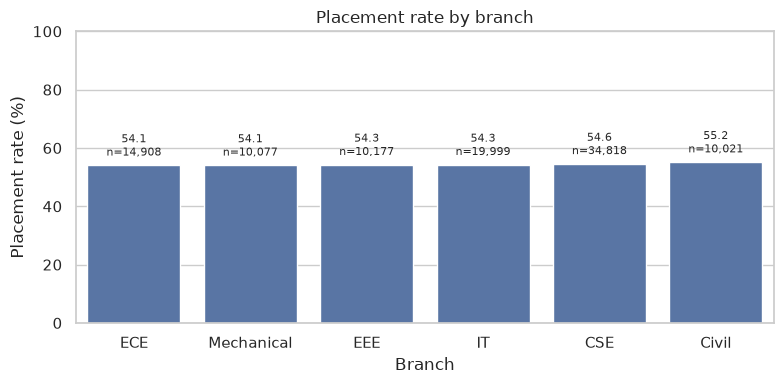

In [16]:
plt.figure(figsize=(8, 4))
sns.barplot(data=branch_tbl, x="branch", y="placement_rate_pct", color="#4C72B0", order=branch_tbl["branch"])
plt.ylim(0, 100)
plt.xlabel("Branch")
plt.ylabel("Placement rate (%)")
plt.title("Placement rate by branch")
for i, row in branch_tbl.reset_index(drop=True).iterrows():
    label = str(row["placement_rate_pct"]) + "\n" + "n=" + format(int(row["students"]), ",")
    plt.text(i, row["placement_rate_pct"] + 2, label, ha="center", va="bottom", fontsize=8)
plt.tight_layout()
plt.show()


The bars are almost the same height. Mechanical and ECE are labelled 54.1, Civil 55.2. On a full 0 to 100 scale that gap is small, which is the same reading as the points-versus-cohort column. Branch is not the chart to use if the goal is to show a difference.


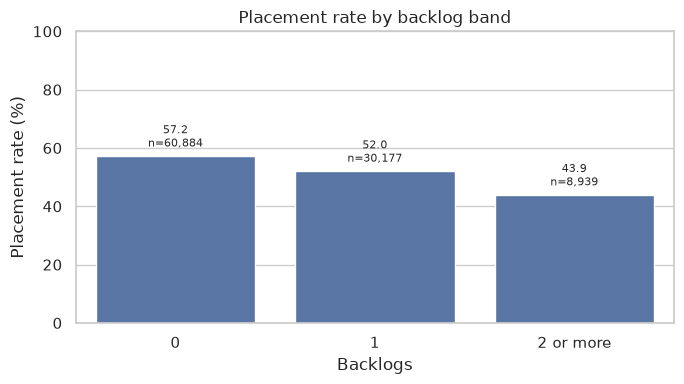

In [17]:
plt.figure(figsize=(7, 4))
sns.barplot(
    data=backlog_tbl,
    x="backlog_band",
    y="placement_rate_pct",
    color="#4C72B0",
    order=backlog_tbl["backlog_band"],
)
plt.ylim(0, 100)
plt.xlabel("Backlogs")
plt.ylabel("Placement rate (%)")
plt.title("Placement rate by backlog band")
for i, row in backlog_tbl.reset_index(drop=True).iterrows():
    label = str(row["placement_rate_pct"]) + "\n" + "n=" + format(int(row["students"]), ",")
    plt.text(i, row["placement_rate_pct"] + 2, label, ha="center", va="bottom", fontsize=8)
plt.tight_layout()
plt.show()


This is the placement chart that does move. The rate steps down from 57.2% with no backlogs, to 52.0% with one, to 43.9% with two or more. The top band still has 8,939 students, so the drop is not a tiny group.


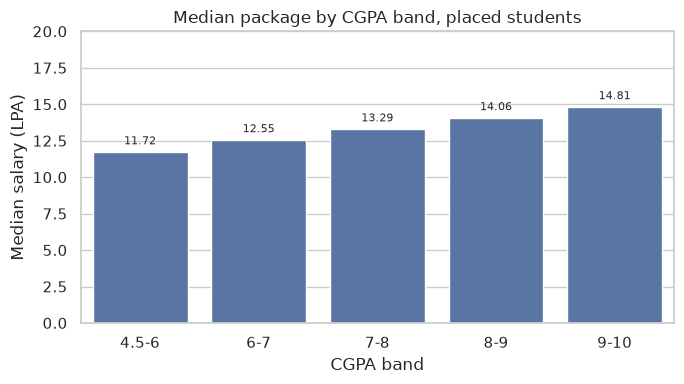

In [18]:
plt.figure(figsize=(7, 4))
sns.barplot(
    data=cgpa_tbl,
    x="cgpa_band",
    y="median_salary_lpa",
    color="#4C72B0",
    order=cgpa_tbl["cgpa_band"],
)
plt.ylim(0, 20)
plt.xlabel("CGPA band")
plt.ylabel("Median salary (LPA)")
plt.title("Median package by CGPA band, placed students")
for i, row in cgpa_tbl.reset_index(drop=True).iterrows():
    label = format(row["median_salary_lpa"], ".2f")
    plt.text(i, row["median_salary_lpa"] + 0.35, label, ha="center", va="bottom", fontsize=8)
plt.tight_layout()
plt.show()


The median package rises with each CGPA band, from 11.72 LPA to 14.81 LPA. The axis starts at 0, and the step is still easy to see. This is the pay chart. It should not be read as a chart of who gets placed: the rate across these same bands only moves from 53.3% to 55.8%.


## 6. Which numeric fields move with the package

The band tables already separate the rate from the pay. This last table asks a narrower question: among placed students, which numeric fields move in a straight line with the package? The number is a Pearson correlation. It is not adjusted for the other fields, and no model is fit. If a field is near zero here, it is not useful as a simple explanation of pay in this file.


In [19]:
placed_numbers = placed.select_dtypes(include="number")
pay_corr = placed_numbers.corr()["salary_package_lpa"]
pay_corr = pay_corr.drop("salary_package_lpa")
pay_corr = pay_corr.reindex(pay_corr.abs().sort_values(ascending=False).index)

pay_corr_table = pay_corr.reset_index()
pay_corr_table.columns = ["field", "pearson_r"]
print("Placed students:", len(placed))
pay_corr_table.round(3)


Placed students: 54459


,field,pearson_r
0,cgpa,0.499
1,coding_skill_score,0.455
2,internships_count,0.392
3,backlogs,0.008
4,projects_count,-0.005
5,attendance_percentage,0.004
6,mock_interview_score,-0.004
7,hackathons_participated,-0.004
8,linkedin_connections,0.004
9,extracurricular_score,0.003


Three fields stand away from the rest. CGPA has a correlation of 0.499 with the package, coding score 0.455, and internships 0.392. Coding score was not in the band charts, but it tracks pay almost as closely as CGPA.

The next field is backlogs, at 0.008. Every remaining field is smaller than that. Projects, attendance, age, study hours, and the other scores do not have a meaningful linear link with the package. That agrees with the backlog table: backlogs change the placement rate and do not change pay.

These correlations describe this file only. They do not say what would happen if a student raised a grade or completed another internship.


## Findings

The file can be summarised as it stands. It has 100,000 rows and, before the identifier was removed, 26 columns. There are no duplicate students, no missing values, no blank labels, and no values outside the rules set at the start. Status and salary agree on every row: 45,541 unplaced students are recorded at 0 LPA, and 54,459 placed students have a positive package. No row was deleted. Pay averages that include the zeros would answer a different question, so they are not used.

Two numbers are enough for the top of a report. The placement rate is 54.5% (54,459 of 100,000). Among placed students the median package is 13.30 LPA and the mean is 13.32 LPA. Quoting either summary gives about 13.3 LPA.

Several slices that a reader might expect to matter do not. Branch rates run from 54.1% to 55.2%, and no branch is more than 0.7 points from the cohort. Gender is 54.4% against 54.5%. College tier is 54.3% to 54.7%. Volunteering is 54.4% against 54.5%. Median pay across gender, tier, volunteering, and branch stays between 13.27 and 13.33 LPA. Those are not meaningful differences in this file.

The branch-by-tier pivot is the exception to that flat picture, and it is a narrow one. EEE Tier 1 is 57.1% placed (2,085 students) and EEE Tier 2 is 52.7% (5,024 students), a 4.4 point gap. Most other cells sit near 54.5%. The table shows the gap. It does not explain it, and it is not a ranking of every branch.

The rate and the package are different stories. No backlogs: 57.2% placed and a median of 13.29 LPA. Two or more backlogs: 43.9% placed and a median of 13.35 LPA. Internships move both, from 50.3% and 12.54 LPA with none to 59.4% and 14.29 LPA with three or more. The median rises by 0.50 LPA from 0 to 1 internship and by another 0.50 LPA from 1 to 2. CGPA barely moves the rate (53.3% to 55.8%) and moves the median package from 11.72 LPA to 14.81 LPA, about 0.7 to 0.8 LPA per band. The correlations add coding score to that pay list (r = 0.455), close to CGPA (r = 0.499) and ahead of internships (r = 0.392). Backlogs, at r = 0.008, do not belong on the pay list.

A short report from this file would lead with the 54.5% rate and the 13.30 LPA median, show backlogs and internships for placement, and show CGPA and coding score for pay. It would keep branch, gender, tier, and volunteering as slices that do not separate students, and it would show the one wider EEE cell with its counts. None of these associations is the effect of changing a student's record. The publisher describes the file as synthetic.


## Limitations and next steps

- The publisher describes the records as synthetic. The audit shows that the columns agree with each other. It does not show that the rows were collected from a real campus, and the results are not a basis for a hiring or pay decision.
- A correlation, or a higher median in a higher CGPA band, is not an estimate of what would happen if a grade or an internship changed.
- Every package figure is limited to students who were placed. The zeros are kept in the file and are not treated as packages.
- The EEE tier gap is one cell in a cross-tab. It is not adjusted for CGPA, backlogs, or internships.
- The top bands pool small tails: 20 students have five or more backlogs, and 96 have seven or more internships. Those raw levels are not quoted as their own rates.
- There is no employer, role, city, or year. Amounts are in LPA.

If this file were replaced by a real extract, the same status check and the same SQL cuts would be the place to start. The slices would be chosen before looking for the widest cell.


In [20]:
# The figures quoted in the text above. This cell fails if a number moves.
assert len(df) == 100000
assert int(df.isnull().sum().sum()) == 0
assert int(range_check["out_of_range"].sum()) == 0
assert n_students == 100000
assert n_placed == 54459
assert round(100 * n_placed / n_students, 1) == 54.5
assert round(float(placed_pay.median()), 2) == 13.30
assert round(float(placed_pay.mean()), 2) == 13.32

assert round(float(branch_tbl["placement_rate_pct"].min()), 1) == 54.1
assert round(float(branch_tbl["placement_rate_pct"].max()), 1) == 55.2
assert round(float(branch_tbl["points_vs_cohort"].abs().max()), 1) == 0.7

assert round(float(backlog_tbl.loc[backlog_tbl["backlog_band"] == "0", "placement_rate_pct"].iloc[0]), 1) == 57.2
assert round(float(backlog_tbl.loc[backlog_tbl["backlog_band"] == "2 or more", "placement_rate_pct"].iloc[0]), 1) == 43.9
assert round(float(backlog_tbl.loc[backlog_tbl["backlog_band"] == "0", "median_salary_lpa"].iloc[0]), 2) == 13.29
assert round(float(backlog_tbl.loc[backlog_tbl["backlog_band"] == "2 or more", "median_salary_lpa"].iloc[0]), 2) == 13.35

assert round(float(internship_tbl.loc[internship_tbl["internship_band"] == "0", "median_salary_lpa"].iloc[0]), 2) == 12.54
assert round(float(internship_tbl.loc[internship_tbl["internship_band"] == "1", "median_salary_lpa"].iloc[0]), 2) == 13.04
assert round(float(internship_tbl.loc[internship_tbl["internship_band"] == "2", "median_salary_lpa"].iloc[0]), 2) == 13.54
assert round(float(internship_tbl.loc[internship_tbl["internship_band"] == "3 or more", "median_salary_lpa"].iloc[0]), 2) == 14.29
assert round(float(internship_tbl.loc[internship_tbl["internship_band"] == "0", "placement_rate_pct"].iloc[0]), 1) == 50.3
assert round(float(internship_tbl.loc[internship_tbl["internship_band"] == "3 or more", "placement_rate_pct"].iloc[0]), 1) == 59.4

assert round(float(cgpa_tbl.loc[cgpa_tbl["cgpa_band"] == "4.5-6", "placement_rate_pct"].iloc[0]), 1) == 53.3
assert round(float(cgpa_tbl.loc[cgpa_tbl["cgpa_band"] == "9-10", "placement_rate_pct"].iloc[0]), 1) == 55.8
assert round(float(cgpa_tbl.loc[cgpa_tbl["cgpa_band"] == "4.5-6", "median_salary_lpa"].iloc[0]), 2) == 11.72
assert round(float(cgpa_tbl.loc[cgpa_tbl["cgpa_band"] == "9-10", "median_salary_lpa"].iloc[0]), 2) == 14.81

assert round(float(pay_corr.loc["cgpa"]), 3) == 0.499
assert round(float(pay_corr.loc["coding_skill_score"]), 3) == 0.455
assert round(float(pay_corr.loc["internships_count"]), 3) == 0.392
assert pay_corr.index[3] == "backlogs"
assert round(abs(float(pay_corr.iloc[3])), 3) == 0.008

assert round(float(rate_pivot.loc["EEE", "Tier 1"]) * 100, 1) == 57.1
assert round(float(rate_pivot.loc["EEE", "Tier 2"]) * 100, 1) == 52.7
assert int(count_pivot.loc["EEE", "Tier 1"]) == 2085
assert int(count_pivot.loc["EEE", "Tier 2"]) == 5024

assert float(pay_by_slice["median_salary_lpa"].min()) == 13.27
assert float(pay_by_slice["median_salary_lpa"].max()) == 13.33
assert int((df["backlogs"] >= 5).sum()) == 20
assert int((df["internships_count"] >= 7).sum()) == 96
print("Quoted figures match the tables.")


Quoted figures match the tables.
